# Detekcija hakerskih napada u CAN mrežama automobila pomoću mašinskog učenja

[HCRL Car-Hacking Dataset](https://ocslab.hksecurity.net/Datasets/car-hacking-dataset)

Detekcija hakerskih napada u CAN mrežama automobila pomoću mašinskog učenja
Elektronski uređaji u automobilu razmjenjuju podatke putem CAN mreže. Tokom snimanja te komunikacije za svaku poruku moguće je zabilježiti vrijeme, identifikator i podatke koje prenosi. U slučaju napada u mrežu se mogu ubaciti dodatne poruke. Tema ovog rada je ispitati kako se takve poruke mogu prepoznati pomoću mašinskog učenja.

U prvom dijelu rada analizirat ću podatke iz skupa HCRL Car-Hacking Dataset. Počet ću od toga kako izgleda jedna zabilježena poruka i šta znači svako njeno polje. Zatim ću provjeriti koliko poruka sadrže odabrane datoteke, koje se vrijednosti ponavljaju i postoje li zapisi koji zahtijevaju dodatnu provjeru. Tako ću upoznati podatke na kojima se zasniva ostatak rada.

Pokretanje. Notebook se pokreće iz foldera koji sadrži podfolder Car-Hacking Dataset. Tabele u tekstu prenio sam iz rada. Kod ispod njih ponavlja izračune iz izvornih datoteka. Za grafikon je potreban matplotlib. Izvor podataka

In [27]:
import csv
import json
import re
import sqlite3
from collections import Counter
from decimal import Decimal
from itertools import groupby, islice
from pathlib import Path
from tempfile import TemporaryDirectory

projekat = Path.cwd()
folder = projekat / "Car-Hacking Dataset"
datoteke = ["DoS_dataset.csv", "Fuzzy_dataset.csv", "gear_dataset.csv", "RPM_dataset.csv"]

for naziv in datoteke:
    if not (folder / naziv).is_file():
        raise FileNotFoundError(folder / naziv)

## 1. Polazni pregled i struktura skupa podataka

### 1.1. Pregled prvih pet zapisa

Tabela 1. Prikaz pet zapisa iz datoteke DoS.

In [28]:
datoteka = folder / "DoS_dataset.csv"

with datoteka.open(encoding="utf-8-sig") as ulaz:
    for red in islice(ulaz, 5):
        print(red.rstrip())

print("\nPrvi zapis sa 6 polja:")
with datoteka.open(encoding="utf-8-sig") as ulaz:
    for broj_reda, red in enumerate(ulaz, start=1):
        polja = red.strip().split(",")
        if len(polja) == 6:
            print(f"Red {broj_reda}: {polja}")
            break

1478198376.389427,0316,8,05,21,68,09,21,21,00,6f,R
1478198376.389636,018f,8,fe,5b,00,00,00,3c,00,00,R
1478198376.389864,0260,8,19,21,22,30,08,8e,6d,3a,R
1478198376.390096,02a0,8,64,00,9a,1d,97,02,bd,00,R
1478198376.390333,0329,8,40,bb,7f,14,11,20,00,14,R

Prvi zapis sa 6 polja:
Red 37: ['1478198376.409484', '05f0', '2', '01', '00', 'R']


### 1.2. Broj zapisa i polja u skupu podataka

Tabela 2. Za svaki zapis provjeravam pravilo **broj polja = DLC + 4**.

In [29]:
ukupno_zapisa = 0
dlc_po_datoteci = {}

for naziv in datoteke:
    broj_zapisa = 0
    prazni_redovi = 0
    broj_odstupanja = 0
    raspodjela_polja = Counter()
    raspodjela_dlc = Counter()

    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if not red:
                prazni_redovi += 1
                continue

            broj_zapisa += 1
            broj_polja = len(red)
            raspodjela_polja[broj_polja] += 1

            try:
                dlc = int(red[2])
            except (IndexError, ValueError):
                broj_odstupanja += 1
                continue

            if not 0 <= dlc <= 8 or broj_polja != dlc + 4:
                broj_odstupanja += 1
            else:
                raspodjela_dlc[dlc] += 1

    dlc_po_datoteci[naziv] = raspodjela_dlc
    ukupno_zapisa += broj_zapisa
    print(f"\n{naziv}")
    print(f"Broj nepraznih zapisa: {broj_zapisa}")
    print(f"Broj praznih redova: {prazni_redovi}")
    for broj_polja, broj_redova in sorted(raspodjela_polja.items()):
        print(f"  Zapisa sa {broj_polja} polja: {broj_redova}")
    print(f"Odstupanja od očekivane dužine prema DLC-u: {broj_odstupanja}")

print(f"\nUkupno zapisa u četiri datoteke: {ukupno_zapisa}")


DoS_dataset.csv
Broj nepraznih zapisa: 3665771
Broj praznih redova: 0
  Zapisa sa 6 polja: 31188
  Zapisa sa 12 polja: 3634583
Odstupanja od očekivane dužine prema DLC-u: 0

Fuzzy_dataset.csv
Broj nepraznih zapisa: 3838860
Broj praznih redova: 0
  Zapisa sa 6 polja: 34382
  Zapisa sa 9 polja: 53451
  Zapisa sa 10 polja: 3
  Zapisa sa 12 polja: 3751024
Odstupanja od očekivane dužine prema DLC-u: 0

gear_dataset.csv
Broj nepraznih zapisa: 4443142
Broj praznih redova: 0
  Zapisa sa 6 polja: 40165
  Zapisa sa 12 polja: 4402977
Odstupanja od očekivane dužine prema DLC-u: 0

RPM_dataset.csv
Broj nepraznih zapisa: 4621702
Broj praznih redova: 0
  Zapisa sa 6 polja: 41476
  Zapisa sa 12 polja: 4580226
Odstupanja od očekivane dužine prema DLC-u: 0

Ukupno zapisa u četiri datoteke: 16569475


### 1.3. Jedinstvene vrijednosti i tipovi podataka

Tipove provjeravam na prvom zapisu, a jedinstvene vrijednosti brojim u sve četiri datoteke.

In [30]:
with (folder / "DoS_dataset.csv").open(encoding="utf-8-sig", newline="") as ulaz:
    prvi_red = next(csv.reader(ulaz))

nazivi = ["Timestamp", "CAN ID", "DLC"]
nazivi.extend(f"DATA[{i}]" for i in range(len(prvi_red[3:-1])))
nazivi.append("Flag")

for naziv, vrijednost in zip(nazivi, prvi_red):
    print(f"{naziv:10} | {vrijednost!r:20} | {type(vrijednost).__name__}")

Timestamp  | '1478198376.389427'  | str
CAN ID     | '0316'               | str
DLC        | '8'                  | str
DATA[0]    | '05'                 | str
DATA[1]    | '21'                 | str
DATA[2]    | '68'                 | str
DATA[3]    | '09'                 | str
DATA[4]    | '21'                 | str
DATA[5]    | '21'                 | str
DATA[6]    | '00'                 | str
DATA[7]    | '6f'                 | str
Flag       | 'R'                  | str


In [31]:
nazivi = ["CAN ID", "DLC", *(f"DATA[{i}]" for i in range(8)), "Flag"]
ucestalosti = {naziv: Counter() for naziv in nazivi}
vremena = set()

for naziv_datoteke in datoteke:
    print(f"Čitam {naziv_datoteke}...", flush=True)
    with (folder / naziv_datoteke).open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if not red:
                continue

            vremena.add(red[0])
            ucestalosti["CAN ID"][red[1]] += 1
            ucestalosti["DLC"][red[2]] += 1
            ucestalosti["Flag"][red[-1]] += 1

            for i, bajt in enumerate(red[3:-1]):
                ucestalosti[f"DATA[{i}]"][bajt] += 1

broj_vremena = len(vremena)
del vremena

print(f"\nUkupno zapisa: {sum(ucestalosti['CAN ID'].values())}")
print(f"Timestamp | različitih vrijednosti: {broj_vremena}")
for naziv, brojac in ucestalosti.items():
    print(f"{naziv} | različitih vrijednosti: {len(brojac)}")

Čitam DoS_dataset.csv...
Čitam Fuzzy_dataset.csv...
Čitam gear_dataset.csv...
Čitam RPM_dataset.csv...

Ukupno zapisa: 16569475
Timestamp | različitih vrijednosti: 13896271
CAN ID | različitih vrijednosti: 2048
DLC | različitih vrijednosti: 4
DATA[0] | različitih vrijednosti: 256
DATA[1] | različitih vrijednosti: 256
DATA[2] | različitih vrijednosti: 256
DATA[3] | različitih vrijednosti: 256
DATA[4] | različitih vrijednosti: 256
DATA[5] | različitih vrijednosti: 256
DATA[6] | različitih vrijednosti: 256
DATA[7] | različitih vrijednosti: 256
Flag | različitih vrijednosti: 2


### 1.4. Sažeti pregled varijabli

Tabela 3. Udio vrijednosti bajta računam među porukama koje imaju tu poziciju.

In [32]:
print(f"{'Varijabla':<12} | {'Tip':<4} | {'Različitih':>11} | Najčešća | Udio (%)")
print(f"{'Timestamp':<12} | {'str':<4} | {broj_vremena:>11} |")
for naziv, brojac in ucestalosti.items():
    if brojac:
        vrijednost, broj_pojava = brojac.most_common(1)[0]
        udio = 100 * broj_pojava / sum(brojac.values())
        print(f"{naziv:<12} | {'str':<4} | {len(brojac):>11} | {vrijednost:>8} | {udio:>7.2f}")
    else:
        print(f"{naziv:<12} | {'str':<4} | {0:>11} |")

Varijabla    | Tip  |  Različitih | Najčešća | Udio (%)
Timestamp    | str  |    13896271 |
CAN ID       | str  |        2048 |     0316 |    8.64
DLC          | str  |           4 |        8 |   98.79
DATA[0]      | str  |         256 |       00 |   33.15
DATA[1]      | str  |         256 |       00 |   39.77
DATA[2]      | str  |         256 |       00 |   54.59
DATA[3]      | str  |         256 |       00 |   42.97
DATA[4]      | str  |         256 |       00 |   41.67
DATA[5]      | str  |         256 |       00 |   34.75
DATA[6]      | str  |         256 |       00 |   57.72
DATA[7]      | str  |         256 |       00 |   52.04
Flag         | str  |           2 |        R |   85.93


### 1.5. Šta predstavlja jedan red i koje se vrijednosti ponavljaju

Jedan red predstavlja CAN poruku. Isti identifikator i ista vremenska oznaka mogu se pojaviti u više redova.

In [33]:
print("Broj poruka:", ukupno_zapisa)
print("Različitih vremenskih oznaka:", broj_vremena)
print("Različitih CAN ID-eva:", len(ucestalosti["CAN ID"]))
print("Poruke s CAN ID-em 0316:", ucestalosti["CAN ID"]["0316"])

Broj poruka: 16569475
Različitih vremenskih oznaka: 13896271
Različitih CAN ID-eva: 2048
Poruke s CAN ID-em 0316: 1431308


## 2. Nedostajući podaci i početna provjera kvalitete

### 2.1. Nedostajuće vrijednosti po varijabli

Tabela 4. DLC određuje koje pozicije bajtova očekujem. Vrijednost 00 je prisutan bajt.

In [34]:
bajtovi = [f"DATA[{i}]" for i in range(8)]
varijable = ["Timestamp", "CAN ID", "DLC", *bajtovi, "Flag"]
nedostaje = dict.fromkeys(varijable, 0)
nije_primjenjivo = dict.fromkeys(varijable, 0)
oznake_nedostajanja = {"", "na", "n/a", "nan", "null", "none", "?"}

ukupno = 0
popunjeno_svih_12 = 0
potpuni_prema_dlc = 0

for naziv in datoteke:
    print(f"Čitam {naziv}...", flush=True)
    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red:
                continue

            dlc = int(red[2])
            if not 0 <= dlc <= 8 or len(red) != dlc + 4:
                raise ValueError(f"Neočekivan raspored: {naziv}, red {broj_reda}")

            ukupno += 1
            nedostaje_u_redu = False
            nazivi_u_redu = ["Timestamp", "CAN ID", "DLC", *bajtovi[:dlc], "Flag"]

            for varijabla, vrijednost in zip(nazivi_u_redu, red):
                if vrijednost.strip().lower() in oznake_nedostajanja:
                    nedostaje[varijabla] += 1
                    nedostaje_u_redu = True

            for varijabla in bajtovi[dlc:]:
                nije_primjenjivo[varijabla] += 1

            if not nedostaje_u_redu:
                potpuni_prema_dlc += 1
                if dlc == 8:
                    popunjeno_svih_12 += 1

print(f"\nUkupno zapisa: {ukupno}")
print("Varijabla | Nedostaje očekivana vrijednost | % svih zapisa | "
      "Nije primjenjivo | % svih zapisa")
for varijabla in varijable:
    broj = nedostaje[varijabla]
    broj_np = nije_primjenjivo[varijabla]
    print(f"{varijabla} | {broj} | {100 * broj / ukupno:.4f}% | "
          f"{broj_np} | {100 * broj_np / ukupno:.4f}%")

Čitam DoS_dataset.csv...
Čitam Fuzzy_dataset.csv...
Čitam gear_dataset.csv...
Čitam RPM_dataset.csv...

Ukupno zapisa: 16569475
Varijabla | Nedostaje očekivana vrijednost | % svih zapisa | Nije primjenjivo | % svih zapisa
Timestamp | 0 | 0.0000% | 0 | 0.0000%
CAN ID | 0 | 0.0000% | 0 | 0.0000%
DLC | 0 | 0.0000% | 0 | 0.0000%
DATA[0] | 0 | 0.0000% | 0 | 0.0000%
DATA[1] | 0 | 0.0000% | 0 | 0.0000%
DATA[2] | 0 | 0.0000% | 147211 | 0.8884%
DATA[3] | 0 | 0.0000% | 147211 | 0.8884%
DATA[4] | 0 | 0.0000% | 147211 | 0.8884%
DATA[5] | 0 | 0.0000% | 200662 | 1.2110%
DATA[6] | 0 | 0.0000% | 200665 | 1.2111%
DATA[7] | 0 | 0.0000% | 200665 | 1.2111%
Flag | 0 | 0.0000% | 0 | 0.0000%


### 2.2. Potpuni i nepotpuni zapisi

In [35]:
print(f"Svih 12 polja popunjeno: {popunjeno_svih_12}")
print(f"Barem jedno od 12 polja bez vrijednosti: {ukupno - popunjeno_svih_12}")
print(f"Sve očekivane vrijednosti prisutne prema DLC-u: {potpuni_prema_dlc}")
print(f"Nedostaje barem jedna očekivana vrijednost: {ukupno - potpuni_prema_dlc}")

Svih 12 polja popunjeno: 16368810
Barem jedno od 12 polja bez vrijednosti: 200665
Sve očekivane vrijednosti prisutne prema DLC-u: 16569475
Nedostaje barem jedna očekivana vrijednost: 0


### 2.3. Potpuno jednaki zapisi i ponovljeni identifikatori

Tabela 5. Poredim sva polja poruke koristeći privremenu SQLite bazu na disku.

In [36]:
def procitaj_zapise(putanja, broj_datoteke):
    with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if red:
                # Čuvam polja tačno kako su učitana, uključujući početne nule.
                zapis = json.dumps(red, separators=(",", ":"))
                yield zapis, broj_datoteke


ponavljanja_unutar = [0] * len(datoteke)
ponavljanja_izmedju = 0
broj_razlicitih_zapisa = 0
broj_zapisa_koji_se_ponavljaju = 0
po_jednom_u_svim_datotekama = 0
ukupno_redova = 0
primjer = None

with TemporaryDirectory(dir=projekat) as privremeni_folder:
    baza = sqlite3.connect(Path(privremeni_folder) / "provjera.db")

    try:
        baza.execute("PRAGMA temp_store = FILE")
        baza.execute("CREATE TABLE poruke (zapis TEXT, datoteka INTEGER)")

        for broj, naziv in enumerate(datoteke):
            print(f"Učitavam {naziv}...", flush=True)
            prije = baza.total_changes

            with baza:
                baza.executemany(
                    "INSERT INTO poruke VALUES (?, ?)",
                    procitaj_zapise(folder / naziv, broj),
                )

            ukupno_redova += baza.total_changes - prije

        print("Poredim zapise iz sve četiri datoteke...", flush=True)
        rezultat = baza.execute("""
            SELECT zapis, datoteka, COUNT(*)
            FROM poruke
            GROUP BY zapis, datoteka
            ORDER BY zapis, datoteka
        """)

        for zapis, grupa in groupby(rezultat, key=lambda red: red[0]):
            pojave = [(broj, kolicina) for _, broj, kolicina in grupa]
            broj_razlicitih_zapisa += 1

            for broj, kolicina in pojave:
                ponavljanja_unutar[broj] += kolicina - 1

            ponavljanja_izmedju += len(pojave) - 1
            broj_pojava = sum(kolicina for _, kolicina in pojave)

            if broj_pojava > 1:
                broj_zapisa_koji_se_ponavljaju += 1
                if primjer is None:
                    primjer = (json.loads(zapis), pojave)

            if len(pojave) == broj_pojava == len(datoteke):
                po_jednom_u_svim_datotekama += 1
    finally:
        baza.close()

print("\nPonavljanja unutar pojedinačnih datoteka:")
for naziv, broj in zip(datoteke, ponavljanja_unutar):
    print(f"{naziv}: {broj}")

print(f"\nUkupno pregledanih redova: {ukupno_redova}")
print(f"Različitih potpunih zapisa: {broj_razlicitih_zapisa}")
print(f"Različitih zapisa koji se pojavljuju više puta: {broj_zapisa_koji_se_ponavljaju}")
print(f"Zapisa koji se pojavljuju po jednom u svakoj datoteci: {po_jednom_u_svim_datotekama}")
print(f"Dodatnih pojavljivanja unutar datoteka: {sum(ponavljanja_unutar)}")
print(f"Dodatnih pojavljivanja između datoteka: {ponavljanja_izmedju}")
print(f"Ukupno dodatnih pojavljivanja: {ukupno_redova - broj_razlicitih_zapisa}")

if primjer:
    zapis, pojave = primjer
    print("\nPrimjer potpuno jednakog zapisa:")
    print(",".join(zapis))
    for broj, kolicina in pojave:
        print(f"  {datoteke[broj]}: {kolicina} puta")

Učitavam DoS_dataset.csv...
Učitavam Fuzzy_dataset.csv...
Učitavam gear_dataset.csv...
Učitavam RPM_dataset.csv...
Poredim zapise iz sve četiri datoteke...

Ponavljanja unutar pojedinačnih datoteka:
DoS_dataset.csv: 0
Fuzzy_dataset.csv: 0
gear_dataset.csv: 0
RPM_dataset.csv: 0

Ukupno pregledanih redova: 16569475
Različitih potpunih zapisa: 13896271
Različitih zapisa koji se pojavljuju više puta: 891068
Zapisa koji se pojavljuju po jednom u svakoj datoteci: 891068
Dodatnih pojavljivanja unutar datoteka: 0
Dodatnih pojavljivanja između datoteka: 2673204
Ukupno dodatnih pojavljivanja: 2673204

Primjer potpuno jednakog zapisa:
1478200727.419470,0545,8,d8,55,00,8a,00,00,00,00,R
  DoS_dataset.csv: 1 puta
  Fuzzy_dataset.csv: 1 puta
  gear_dataset.csv: 1 puta
  RPM_dataset.csv: 1 puta


### 2.4. Provjera ispravnosti vrijednosti

Tabela 6. Provjeravam format vremena, redoslijed zapisa, CAN ID, bajtove i oznake.

In [37]:
format_vremena = re.compile(r"[0-9]+(?:\.[0-9]+)?")
format_id = re.compile(r"[0-9a-fA-F]+")
format_bajta = re.compile(r"[0-9a-fA-F]{2}")

for naziv in datoteke:
    print(f"\nProvjeravam {naziv}...", flush=True)

    broj_zapisa = 0
    neispravno_vrijeme = 0
    vrijeme_unazad = 0
    neispravan_id = 0
    broj_bajtova = 0
    neispravni_bajtovi = 0
    neocekivana_oznaka = 0

    prethodno_vrijeme = None
    najmanje_vrijeme = None
    najvece_vrijeme = None
    duzine_id = Counter()
    primjeri = {}

    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red:
                continue

            broj_zapisa += 1
            vrijeme, can_id = red[0], red[1]
            oznaka = red[-1]

            if format_vremena.fullmatch(vrijeme):
                trenutno = Decimal(vrijeme)

                if prethodno_vrijeme is not None and trenutno < prethodno_vrijeme:
                    vrijeme_unazad += 1
                    primjeri.setdefault(
                        "Vrijeme ide unazad",
                        (broj_reda, f"{prethodno_vrijeme} -> {trenutno}"),
                    )

                prethodno_vrijeme = trenutno
                if najmanje_vrijeme is None or trenutno < najmanje_vrijeme:
                    najmanje_vrijeme = trenutno
                if najvece_vrijeme is None or trenutno > najvece_vrijeme:
                    najvece_vrijeme = trenutno
            else:
                neispravno_vrijeme += 1
                primjeri.setdefault("Format vremena", (broj_reda, vrijeme))
                prethodno_vrijeme = None

            if format_id.fullmatch(can_id):
                duzine_id[len(can_id)] += 1
            else:
                neispravan_id += 1
                primjeri.setdefault("Format CAN ID-a", (broj_reda, can_id))

            for pozicija, bajt in enumerate(red[3:-1]):
                broj_bajtova += 1
                if not format_bajta.fullmatch(bajt):
                    neispravni_bajtovi += 1
                    primjeri.setdefault(
                        "Format bajta", (broj_reda, f"DATA[{pozicija}] = {bajt!r}")
                    )

            if oznaka not in {"R", "T"}:
                neocekivana_oznaka += 1
                primjeri.setdefault("Oznaka poruke", (broj_reda, oznaka))

    print(f"Pregledano zapisa: {broj_zapisa}")
    print(f"Neispravan format vremena: {neispravno_vrijeme}")
    print(f"Vrijeme ide unazad: {vrijeme_unazad}")
    if najmanje_vrijeme is not None:
        print(f"Vremenski raspon snimka (s): {najvece_vrijeme - najmanje_vrijeme}")
    print(f"CAN ID s neheksadecimalnim zapisom: {neispravan_id}")
    print(f"Dužina CAN ID-a (broj znakova: broj zapisa): {dict(duzine_id)}")
    print(f"Pregledano prisutnih bajtova: {broj_bajtova}")
    print(f"Bajtova s neispravnim zapisom: {neispravni_bajtovi}")
    print(f"Oznaka izvan R/T: {neocekivana_oznaka}")

    for provjera, (broj_reda, vrijednost) in primjeri.items():
        print(f"Prvi primjer – {provjera}, red {broj_reda}: {vrijednost}")


Provjeravam DoS_dataset.csv...
Pregledano zapisa: 3665771
Neispravan format vremena: 0
Vrijeme ide unazad: 0
Vremenski raspon snimka (s): 2832.669517
CAN ID s neheksadecimalnim zapisom: 0
Dužina CAN ID-a (broj znakova: broj zapisa): {4: 3665771}
Pregledano prisutnih bajtova: 29139040
Bajtova s neispravnim zapisom: 0
Oznaka izvan R/T: 0

Provjeravam Fuzzy_dataset.csv...
Pregledano zapisa: 3838860
Neispravan format vremena: 0
Vrijeme ide unazad: 0
Vremenski raspon snimka (s): 5487.155067
CAN ID s neheksadecimalnim zapisom: 0
Dužina CAN ID-a (broj znakova: broj zapisa): {4: 3838860}
Pregledano prisutnih bajtova: 30344229
Bajtova s neispravnim zapisom: 0
Oznaka izvan R/T: 0

Provjeravam gear_dataset.csv...
Pregledano zapisa: 4443142
Neispravan format vremena: 0
Vrijeme ide unazad: 0
Vremenski raspon snimka (s): 8019.002378
CAN ID s neheksadecimalnim zapisom: 0
Dužina CAN ID-a (broj znakova: broj zapisa): {4: 4443142}
Pregledano prisutnih bajtova: 35304146
Bajtova s neispravnim zapisom: 0


### 2.5. Obrazac nepopunjenih polja

Tabela 7. Brojeve poruka po DLC-u preuzimam iz 1.2.

In [38]:
print("DLC | Broj poruka | Posljednji upisani bajt | Neprimjenjiva polja | Datoteke")
duzine = sorted({dlc for brojac in dlc_po_datoteci.values() for dlc in brojac})
for dlc in duzine:
    broj_poruka = sum(brojac[dlc] for brojac in dlc_po_datoteci.values())
    posljednji = f"DATA[{dlc - 1}]" if dlc else "nema"
    pozicije = ", ".join(bajtovi[dlc:]) or "nema"
    izvori = ", ".join(ime for ime, brojac in dlc_po_datoteci.items() if brojac[dlc])
    print(f"{dlc} | {broj_poruka} | {posljednji} | {pozicije} | {izvori}")

DLC | Broj poruka | Posljednji upisani bajt | Neprimjenjiva polja | Datoteke
2 | 147211 | DATA[1] | DATA[2], DATA[3], DATA[4], DATA[5], DATA[6], DATA[7] | DoS_dataset.csv, Fuzzy_dataset.csv, gear_dataset.csv, RPM_dataset.csv
5 | 53451 | DATA[4] | DATA[5], DATA[6], DATA[7] | Fuzzy_dataset.csv
6 | 3 | DATA[5] | DATA[6], DATA[7] | Fuzzy_dataset.csv
8 | 16368810 | DATA[7] | nema | DoS_dataset.csv, Fuzzy_dataset.csv, gear_dataset.csv, RPM_dataset.csv


## 3. Razvrstavanje varijabli prema mjernoj ljestvici

### 3.1. Podjela varijabli prema mjernoj ljestvici

**Tabela 8. Razvrstavanje varijabli prema mjernoj ljestvici**

| Varijabla | Vrsta varijable |
|---|---|
| Timestamp | Kvantitativna, kontinuirana |
| CAN ID | Kvalitativna, nominalna |
| DLC | Kvantitativna, diskretna |
| DATA[0] do DATA[7] | Kvantitativne, diskretne na nivou pojedinačnog bajta |
| Flag | Kvalitativna, nominalna |

### 3.2. Obrazloženje klasifikacije

CAN ID je oznaka grupe. DLC broji bajtove. Timestamp mjeri vrijeme, a DATA polja predstavljaju pojedinačne bajtove. Flag razlikuje redovne i ubačene poruke.

### 3.3. Vremenske, tekstualne i identifikacijske varijable

Razmake između poruka mogu izvesti iz Timestamp-a unutar snimka. CAN ID čuvam s početnim nulama i koristim za grupisanje. Flag koristim za brojanje poruka s oznakama R i T.

### 3.4. Poredak kategorija

CAN ID i Flag imaju kategorije bez prirodnog redoslijeda. U skupu nema ordinalnih varijabli.

## 4. Deskriptivna analiza kvalitativnih varijabli

### 4.1. Zastupljenost redovnih i ubačenih poruka

Čitam DoS_dataset.csv...
Čitam Fuzzy_dataset.csv...
Čitam gear_dataset.csv...
Čitam RPM_dataset.csv...

Tabela 9. Zastupljenost redovnih i ubačenih CAN poruka
Oznaka	Broj poruka	Udio
R	14.237.958	85,93 %
T	2.331.517	14,07 %
Ukupno	16.569.475	100,00 %
Broj različitih kategorija: 2


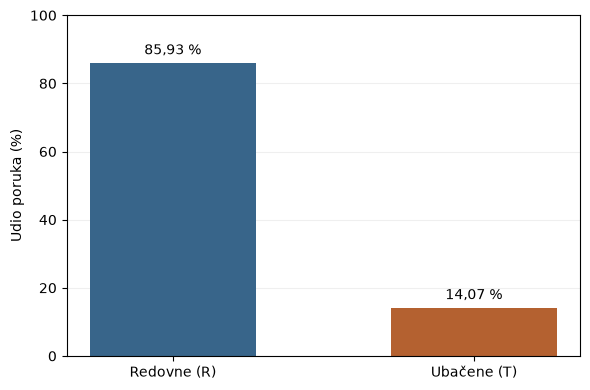

In [39]:
import matplotlib.pyplot as plt

broj_poruka = Counter()
for naziv in datoteke:
    print(f"Čitam {naziv}...", flush=True)
    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red or red[-1] not in ("R", "T"):
                raise ValueError(f"{naziv}, red {broj_reda}: očekivana je oznaka R ili T.")
            broj_poruka[red[-1]] += 1


def format_broja(broj):
    return f"{broj:,}".replace(",", ".")


def format_procenta(procenat):
    return f"{procenat:.2f}".replace(".", ",") + " %"


ukupno_oznaka = sum(broj_poruka.values())
if ukupno_oznaka != 16_569_475:
    raise ValueError(
        f"Pročitano je {format_broja(ukupno_oznaka)} zapisa, "
        "a u prethodnoj analizi bilo ih je 16.569.475."
    )

oznake = ["R", "T"]
procenti = [100 * broj_poruka[oznaka] / ukupno_oznaka for oznaka in oznake]

print("\nTabela 9. Zastupljenost redovnih i ubačenih CAN poruka")
print("Oznaka\tBroj poruka\tUdio")
for oznaka, procenat in zip(oznake, procenti):
    print(f"{oznaka}\t{format_broja(broj_poruka[oznaka])}\t{format_procenta(procenat)}")
print(f"Ukupno\t{format_broja(ukupno_oznaka)}\t100,00 %")
print(f"Broj različitih kategorija: {len(broj_poruka)}")

fig, ax = plt.subplots(figsize=(6, 4))
stubovi = ax.bar(
    ["Redovne (R)", "Ubačene (T)"],
    procenti,
    color=["#38658A", "#B46130"],
    width=0.55,
)
ax.set_ylabel("Udio poruka (%)")
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.bar_label(stubovi, labels=[format_procenta(p) for p in procenti], padding=4)

fig.tight_layout()
fig.savefig(projekat / "grafikon_1_flag.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Grafikon 1. Udio redovnih i ubačenih CAN poruka**

Redovne poruke čine 85,93 % četiri analizirana snimka. Na jednu ubačenu poruku dolazi približno šest redovnih.

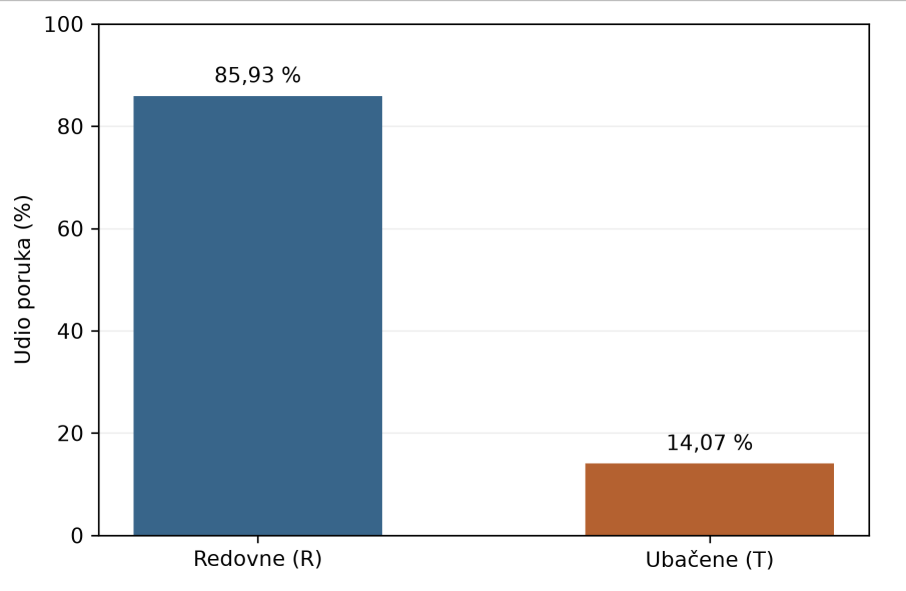